**Medical Insurance Cost Prediction Using Supervised Machine Learning**

**Dataset**: Kaggle Medical Insurance Dataset

**Algorithms Used**:

Linear Regression

Generalized Linear Model (GLM)

Support Vector Regression (SVR)

**Objective**:
To predict medical insurance charges based on demographic and lifestyle features using supervised machine learning techniques.

**Dataset Description**:

The dataset used in this project is the Medical Insurance Dataset obtained from Kaggle.
It contains demographic and health-related information about individuals along with the medical insurance charges billed to them.

**Features in the Dataset**:
| Feature      | Description                                                             |
| ------------ | ----------------------------------------------------------------------- |
| **age**      | Age of the insured person                                               |
| **sex**      | Gender of the individual                                                |
| **bmi**      | Body Mass Index (BMI), a measure of body fat based on height and weight |
| **children** | Number of dependents covered by insurance                               |
| **smoker**   | Indicates whether the person is a smoker or non-smoker                  |
| **region**   | Residential region in the United States                                 |
| **charges**  | Medical insurance cost billed to the individual                         |


**Target Variable**:

The variable charges is the target variable that the machine learning models aim to predict. It represents the total medical insurance cost for an individual.

**Methodology**

The following steps are followed to build the machine learning models:

1.Dataset Collection

2.Data Exploration and Visualization

3.Data Preprocessing

4.Feature Encoding

5.Train-Test Split

6.Model Training

7.Linear Regression

8.Generalized Linear Model

9.Support Vector Regression

10.Model Evaluation using MSE and R²

11.Model Comparison and Analysis

#Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
import statsmodels.api as sm

#Upload Dataset

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving insurance.csv to insurance (11).csv


#Load Dataset

In [ ]:
data = pd.read_csv("insurance.csv")
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


#Dataset Information

In [ ]:
data.info()
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


#Check Missing Values

In [ ]:
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


#Distribution of Insurance Charges

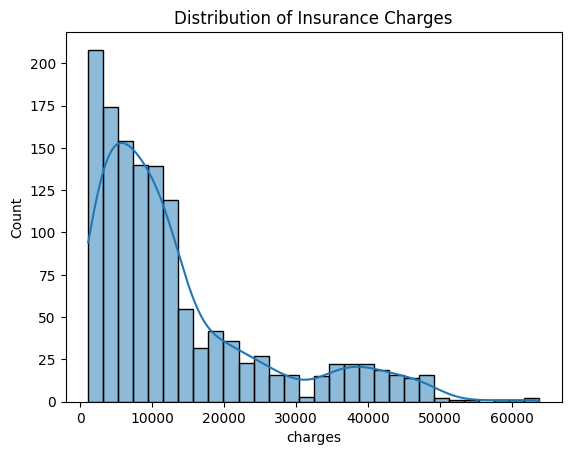

In [ ]:
sns.histplot(data['charges'], kde=True)
plt.title("Distribution of Insurance Charges")
plt.show()

#Correlation Heatmap

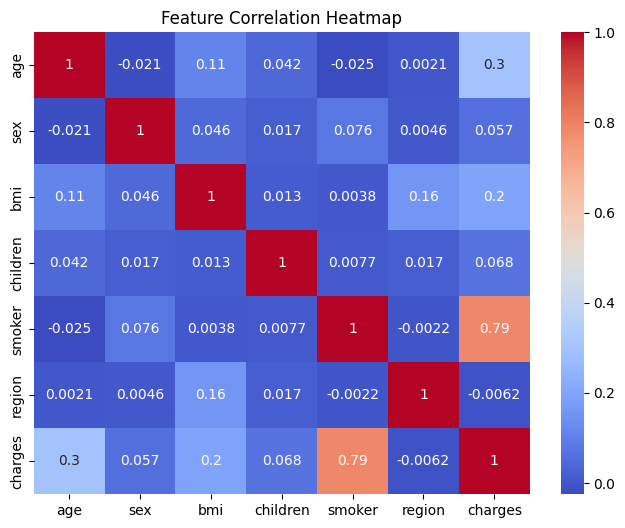

In [ ]:
plt.figure(figsize=(8,6))
data_for_corr = data.copy()
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data_for_corr['sex'] = le.fit_transform(data_for_corr['sex'])
data_for_corr['smoker'] = le.fit_transform(data_for_corr['smoker'])
data_for_corr['region'] = le.fit_transform(data_for_corr['region'])
corr = data_for_corr.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

#Age vs Charges

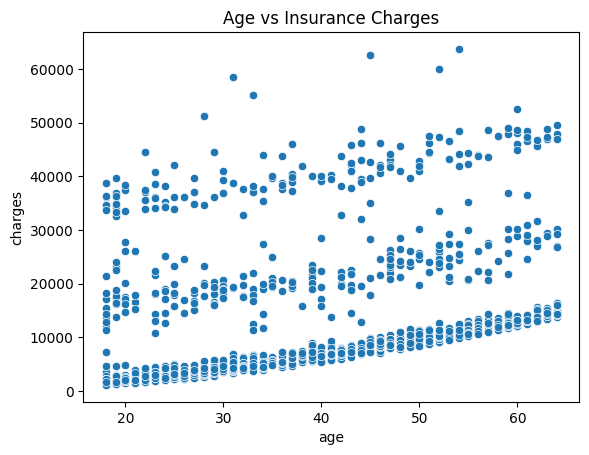

In [ ]:
sns.scatterplot(x='age', y='charges', data=data)
plt.title("Age vs Insurance Charges")
plt.show()

#BMI vs Charges

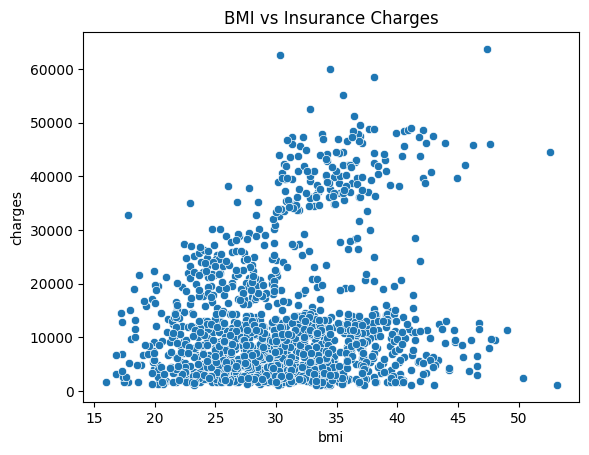

In [ ]:
sns.scatterplot(x='bmi', y='charges', data=data)
plt.title("BMI vs Insurance Charges")
plt.show()

#Smoking Status vs Charges

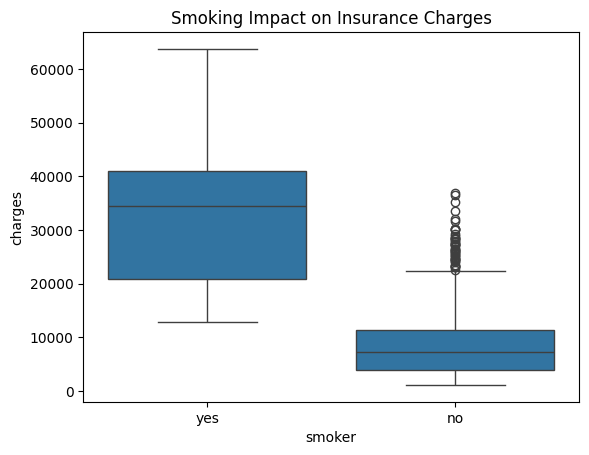

In [ ]:
sns.boxplot(x='smoker', y='charges', data=data)
plt.title("Smoking Impact on Insurance Charges")
plt.show()

#Encode Categorical Variables

In [ ]:
le = LabelEncoder()
data['sex'] = le.fit_transform(data['sex'])
data['smoker'] = le.fit_transform(data['smoker'])
data['region'] = le.fit_transform(data['region'])
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520


#Define Features and Target

In [ ]:
X = data.drop('charges', axis=1)
y = data['charges']

#Train Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#Feature Scaling

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#Linear Regression

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)
print("Linear Regression MSE:", mse_lr)
print("Linear Regression R2 Score:", r2_lr)

Linear Regression MSE: 33635210.43117845
Linear Regression R2 Score: 0.7833463107364536


#Graph

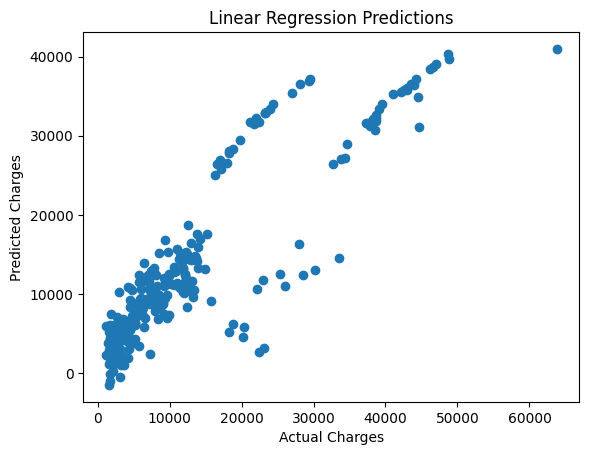

In [ ]:
plt.scatter(y_test, y_pred_lr)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Linear Regression Predictions")
plt.show()

#Generalized Linear Model (GLM)

In [ ]:
X_glm = sm.add_constant(X)

glm_model = sm.GLM(
    y,
    X_glm,
    family=sm.families.Gamma(link=sm.families.links.Log())
)

glm_results = glm_model.fit()

print(glm_results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                charges   No. Observations:                 1338
Model:                            GLM   Df Residuals:                     1331
Model Family:                   Gamma   Df Model:                            6
Link Function:                    Log   Scale:                         0.46495
Method:                          IRLS   Log-Likelihood:                -13306.
Date:                Thu, 12 Mar 2026   Deviance:                       338.15
Time:                        14:25:46   Pearson chi2:                     619.
No. Iterations:                    18   Pseudo R-squ. (CS):             0.6846
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.3956      0.107     68.811      0.0

#Prediction

In [ ]:
glm_pred = glm_results.predict(X_glm)
mse_glm = mean_squared_error(y, glm_pred)
r2_glm = r2_score(y, glm_pred)
print("GLM MSE:", mse_glm)
print("GLM R2 Score:", r2_glm)

GLM MSE: 60491410.99007218
GLM R2 Score: 0.5872098470808143


#Graph

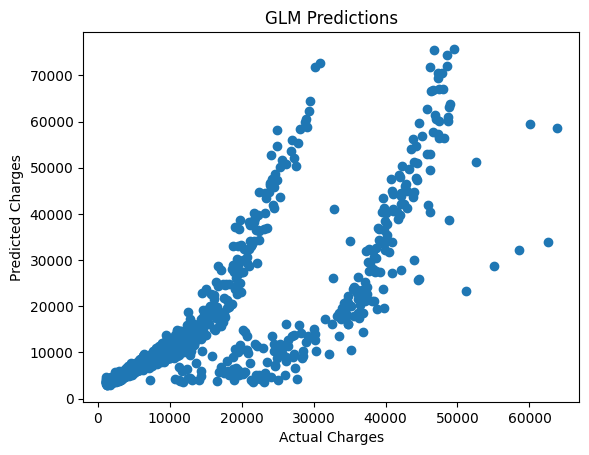

In [ ]:
plt.scatter(y, glm_pred)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("GLM Predictions")
plt.show()

#Support Vector Regression (SVR)

In [ ]:
svr = SVR(kernel='rbf')
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)
mse_svr = mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)
print("SVR MSE:", mse_svr)
print("SVR R2 Score:", r2_svr)

SVR MSE: 165839509.92452022
SVR R2 Score: -0.06821813183902203


#Graph

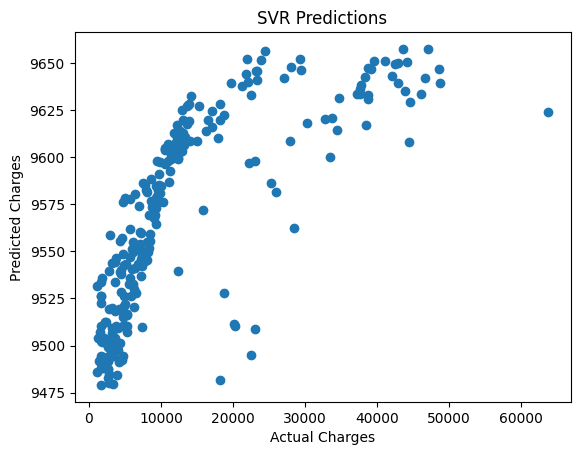

In [ ]:
plt.scatter(y_test, y_pred_svr)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("SVR Predictions")
plt.show()

#Model Comparison

In [ ]:
results = pd.DataFrame({
"Model": ["Linear Regression", "GLM", "SVR"],
"MSE": [mse_lr, mse_glm, mse_svr],
"R2 Score": [r2_lr, r2_glm, r2_svr]
})
print(results)

               Model           MSE  R2 Score
0  Linear Regression  3.363521e+07  0.783346
1                GLM  6.049141e+07  0.587210
2                SVR  1.658395e+08 -0.068218


#Comparison Graph

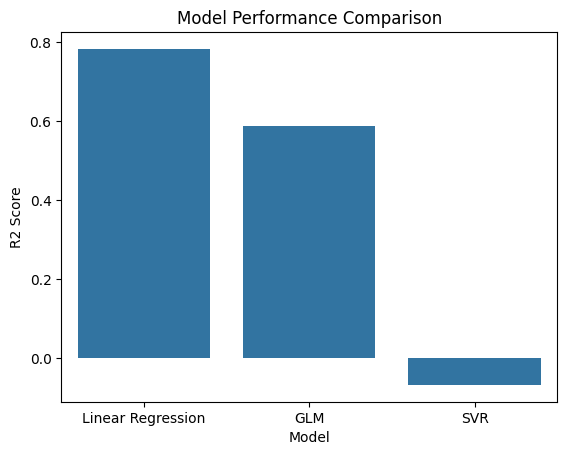

In [ ]:
sns.barplot(x="Model", y="R2 Score", data=results)
plt.title("Model Performance Comparison")
plt.show()

#conclusion:

In this project, medical insurance charges were predicted using supervised machine learning models. Linear Regression, Generalized Linear Models, and Support Vector Regression were implemented and compared. The models were evaluated using Mean Squared Error and R² score. The comparison helps determine the most suitable model for predicting insurance costs based on demographic and lifestyle features.